# 05 基于 NetworkX 的最小生成树算法

> **模块**：图论与网络 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib、networkx

## 1. 问题背景

树是图论中非常重要的一类图，它非常类似于自然界中的树，结构简单、应用广泛，最小生成树问题是其中的经典问题之一。在实际应用中，许多问题的图论模型都是最小生成树，如通信网络建设、有线电缆铺设、加工设备分组等。


## 2. 学习目标

- 掌握 Kruskal 算法的思路
- 掌握 Prim 算法的思路
- 掌握使用 NetworkX 计算最小生成树


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 最小生成树

#### 4.1.1 基本概念

定义1. 连通的无圈图称为树。

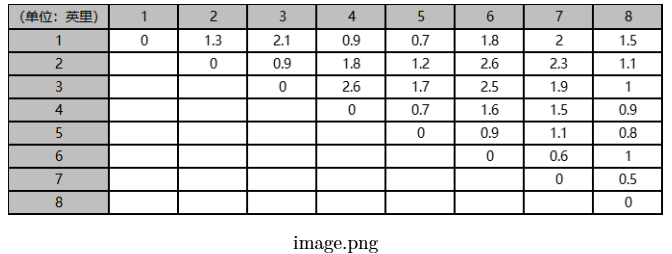

如上图，$G_1$是树，但是$G_2$和$G_3$则不是树。
定理1. 连通图的生成树一定存在。

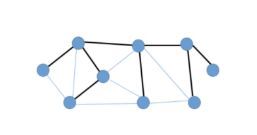

如上图，加粗黑线为连通图的最小生成树。

### 4.2 最小生成树算法

对于赋权连接图$G=(V,E,W)$，其中$V$为顶点集合，$E$为边的集合，$W$为邻接矩阵，这里顶点集合$V$中有$n$个顶点，构造它的最小生成树。构造连通图最小生成树的算法有Kruskal算法和Prim算法。

#### 4.2.1 Kruskal 算法

**Kruskal算法思想：每次将一条权最小的边加入子图$T$中，并保证不形成圈。**

Kruskal算法步骤如下：
1. 选$e_1 \in E$，使得$e_1$是权值最小的边。
2. 若$e_1,e_2,\ldots,e_i$已选好，则从$E - \{e_1,e_2,\ldots,e_i\}$中选择，使得：

$\quad$（1）$\{e_1,e_2,\ldots,e_i,e_{i+1}\}$中无圈

$\quad$（2）$e_{i+1}$是$E - \{e_1,e_2,\ldots,e_i\}$中权值最小的边。
3. 直到选到$e_{n-1}$为止。

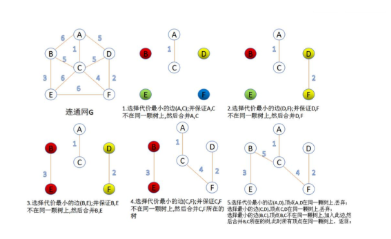

如上图连通图$G$：
1. 选择边(A,C)是权值最小的边。
2. 选择边(D,F)是权值第二小的边，并且(A,C)和(D,F)中无圈。
3. 选择边(B,E)是权值第三小的边，并且(A,C)、(D,F)和(B,E)中无圈。
4. 选择边(C,F)是权值第四小的边，并且(A,C)、(D,F)、(B,E)和(C,F)中无圈。
5. 选择边(B,C)是权值第五小的边，并且(A,C)、(D,F)、(B,E)、(C,F)和(B,C)中无圈（相同权值的边因为加入后形成圈，所以舍弃）。

用Kruskal算法求如下图所示连通图的最小生成树。

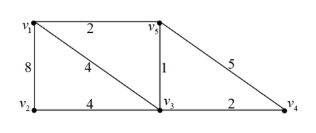


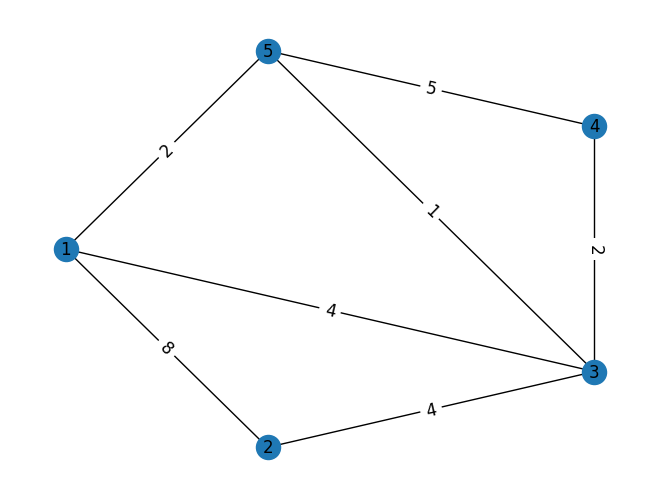

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

L = [(1,2,8),(1,3,4),(1,5,2),(2,3,4),(3,4,2),(3,5,1),(4,5,5)] # 定义边和权重
G = nx.Graph()  # 创建无向图
G.add_nodes_from(range(1,6)) # 添加顶点
G.add_weighted_edges_from(L)  # 添加边
pos=nx.shell_layout(G)  # 节点在同心圆上分布
w = nx.get_edge_attributes(G,'weight')  # 从G中获取边的权值
# 绘图
nx.draw(G,pos,with_labels=True)
nx.draw_networkx_edge_labels(G,pos,font_size=12,edge_labels=w)
plt.show()

#### 4.2.2 NetworkX 求最小生成树函数

`networkx.minimum_spanning_tree(G, weight='weight', algorithm='kruskal', ignore_nan=False)`

#### 4.2.3 参数说明

- **G**: 输入的图对象，类型为`networkx.Graph`，可以是带有权重的图。
- **weight**: 权重属性的名称，默认为`'weight'`。可以更改为图中用作边权重的任何属性名。
- **algorithm**: 指定使用的算法。此参数可以取以下值：
- `'kruskal'`：使用Kruskal算法构造最小生成树。
- `'prim'`：使用Prim算法构造最小生成树。
- `'boruvka'`：使用Boruvka算法构造最小生成树。
- **ignore_nan**: 布尔值，默认为`False`。如果设置为`True`，在边的权重中遇到`NaN`值时，该边将被忽略。

#### 4.2.4 返回值

返回值为所求得的最小生成树的可迭代对象，通常是`networkx`图对象，包含最小生成树中的边。

In [14]:
import networkx as nx
# 返回可迭代对象
T = nx.minimum_spanning_tree(G,algorithm='kruskal')  
# 提取字典数据(边:权重)
w = nx.get_edge_attributes(T,'weight')
# 计算最小生成树的长度（边对应权值相加）
TL = sum(w.values())  
print("最小生成树为:",w)
print("最小生成树的长度为：",TL)

最小生成树为: {(1, 5): 2, (2, 3): 4, (3, 5): 1, (3, 4): 2}
最小生成树的长度为： 9


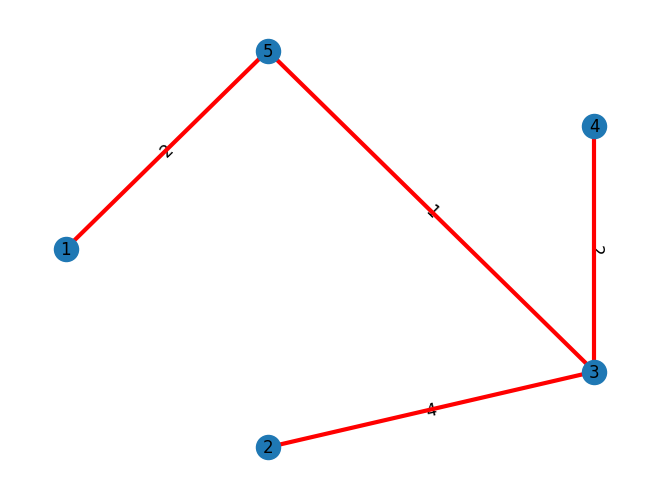

In [15]:
# 绘图
nx.draw(T,pos,with_labels=True)
# 绘制边的权重
nx.draw_networkx_edge_labels(T,pos,font_size=12,edge_labels=w)
# 绘制边，改变颜色
nx.draw_networkx_edges(T,pos,edgelist=w.keys(),
             edge_color='r',width=3)
plt.show()

#### 4.2.5 Prim 算法

Prim算法是一种贪心算法，其操作策略与Kruskal算法有所不同。Kruskal算法侧重于边的操作，而Prim算法则通过节点的逐步添加来构建最小生成树。具体而言，Prim算法在每一步中选择一条连接集合$P$中的节点与集合$V-P$中节点的最小权重边，并将该边的另一端节点加入集合$P$中。

设两个集合$P$和$Q$，其中集合$P$用于存放图$G$的最小生成树中的顶点，而集合$Q$则用于存放最小生成树中的边。集合$P$的初始状态为$P = \{v_1\}$（假设从顶点$v_1$开始构建最小生成树），集合$Q$的初始状态为空集$Q = \varnothing$。

Prim算法的核心思想在于：从所有$p \in P, v \in V - P$的边中，选取具有最小权值的边$pv$，将顶点$v$加入集合$P$，同时将边$pv$加入集合$Q$。这一过程不断重复，直到集合$P$中包含图$G$的所有顶点，即$P = V$时，最小生成树构建完成，此时集合$Q$中包含了最小生成树的所有边。

**Prim算法步骤**：
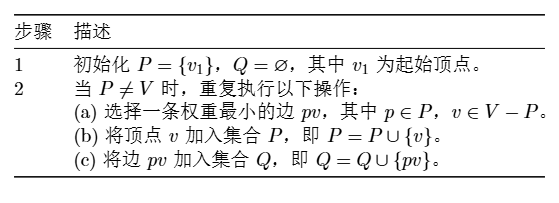

| 步骤 | 描述                                                                                                                                                        |
|------|-------------------------------------------------------------------------------------------------------------------------------------------------------------|
| 1    | 初始化$P = \{v_1\}$，$Q = \varnothing$，其中$v_1$为起始顶点。                                                                                              |
| 2    | 当$P \neq V$时，重复执行以下操作：                                                                                                                            |
|      | (a) 选择一条权重最小的边$pv$，其中$p \in P$，$v \in V - P$。                                                                                                    |
|      | (b) 将顶点$v$加入集合$P$，即$P = P \cup \{v\}$。                                                                                                                |
|      | (c) 将边$pv$加入集合$Q$，即$Q = Q \cup \{pv\}$。                                                                                                                |

**表1** Prim算法的主要步骤。该表详细列出了Prim算法的两个主要阶段及其操作步骤，从初始化到最终生成最小生成树的过程。
Prim算法如下：

1. $P = \{v_1\}, Q = ∅$
2. `while P ≠ V`
- 找最小边 $pv$，其中 $p \in P, v \in V - P$；
- $P = P + \{v\}$；
- $Q = Q + \{pv\}$；
- `end`

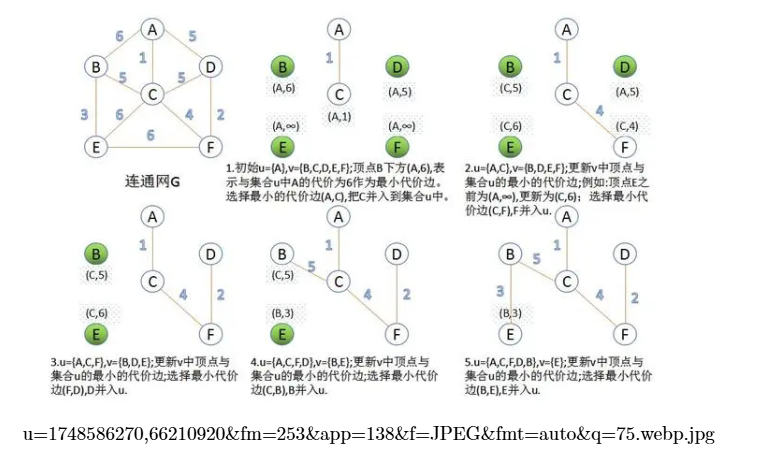

如上图连通图G，使用Prim算法求最小生成树
1. 初始化，顶点集$P = \{A\},Q = ∅$
2. 找到最小边$(A,C)$，$P = \{A,C\},Q = \{(A,C)\}$
3. 找到最小边$pv$($p∈P,v∈V-P$)为$(C,F)$，$P = \{A,C,F\},Q = \{(A,C),(C,F)\}$
4. 找到最小边$(D,F)$，$P = \{A,C,D,F\},Q = \{(A,C),(C,F),(D,F)\}$
5. 找到最小边$(B,C)$，$P = \{A,B,C,D,F\},Q = \{(A,C),(C,F),(D,F),(B,C)\}$
6. 找到最小边$(B,E)$，$P = \{A,B,C,D,E,F\},Q = \{(A,C),(C,F),(D,F),(B,C),(B,E)\}$

此时，$P＝V$。


最小生成树为: {(1, 5): 2, (2, 3): 4, (3, 5): 1, (3, 4): 2}
最小生成树的长度为： 9


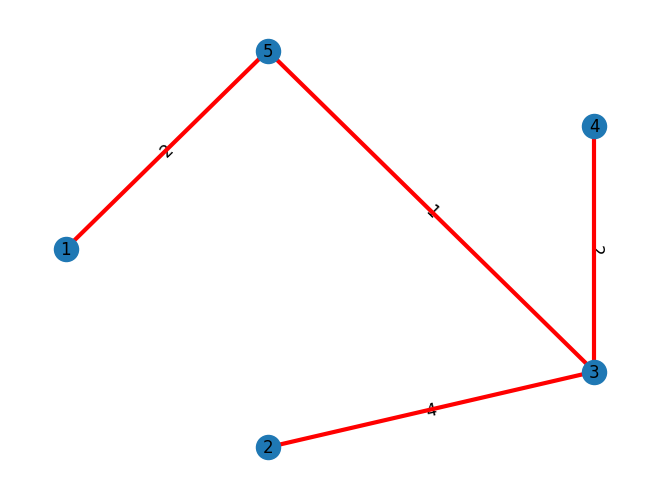

In [16]:
# 返回可迭代对象
T = nx.minimum_spanning_tree(G, algorithm='prim')  # 使用Prim算法计算最小生成树

# 提取字典数据(边:权重)
w = nx.get_edge_attributes(T, 'weight')  # 获取最小生成树的边及其权重

# 计算最小生成树的长度（边对应权值相加）
TL = sum(w.values())  # 计算最小生成树的总权重
print("最小生成树为:", w)  # 输出最小生成树的边及其权重
print("最小生成树的长度为：", TL)  # 输出最小生成树的总权重

nx.draw(T, pos, with_labels=True)  # 绘制最小生成树，显示节点标签

# 绘制边的权重
nx.draw_networkx_edge_labels(T, pos, font_size=12, edge_labels=w)  # 在图上显示边的权重

# 绘制边，改变颜色
nx.draw_networkx_edges(T, pos, edgelist=w.keys(), edge_color='r', width=3)  # 以红色宽边绘制最小生成树的边
plt.show()  


对于上例，两种方法中间过程虽然不同，但是最终结果是相同的。

### 4.3 油管铺设问题应用

有8口海上油井，相互间距离如下表所示（单位：海里），其中1号油井离海岸线最近，为5海里。先要从海岸经1号井铺设油管将各井连接起来，则应如何铺设使油管长度最短。

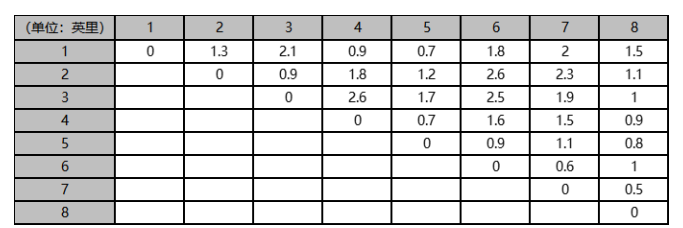

以上表格数据保存在 `../data/Oil pipeline.xlsx` 文件中。


In [17]:
data =pd.read_excel('../data/Oil pipeline.xlsx')

In [18]:
A = data.values  # 转换为邻接矩阵A

# np.isnan(A)判断是否是空值
# 将矩阵A中的空值赋值为0
A[np.isnan(A)]=0
A

array([[0. , 1.3, 2.1, 0.9, 0.7, 1.8, 2. , 1.5],
       [0. , 0. , 0.9, 1.8, 1.2, 2.6, 2.3, 1.1],
       [0. , 0. , 0. , 2.6, 1.7, 2.5, 1.9, 1. ],
       [0. , 0. , 0. , 0. , 0.7, 1.6, 1.5, 0.9],
       [0. , 0. , 0. , 0. , 0. , 0.9, 1.1, 0.8],
       [0. , 0. , 0. , 0. , 0. , 0. , 0.6, 1. ],
       [0. , 0. , 0. , 0. , 0. , 0. , 0. , 0.5],
       [0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. ]])

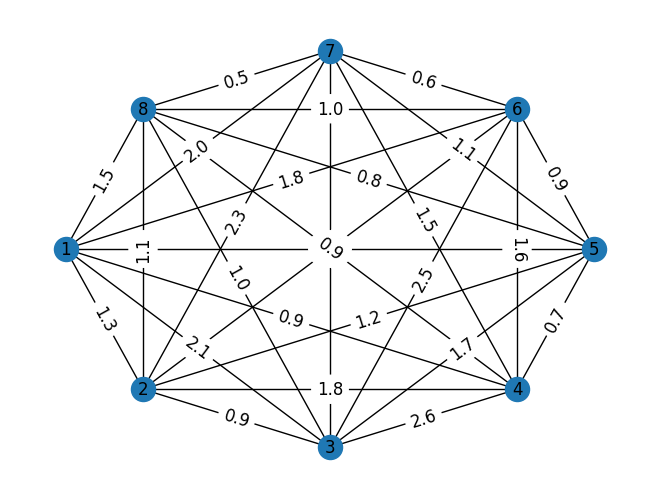

In [19]:

G = nx.Graph(A)  # 通过邻接矩阵创建无向图
pos=nx.shell_layout(G) # 节点在同心圆上分布
w = nx.get_edge_attributes(G,'weight') # 从G中获取边的权值
s = dict(zip(range(8),range(1,9)))   # 构造用于顶点标注的标号字典

nx.draw(G,pos,with_labels=True,labels = s)
nx.draw_networkx_edge_labels(G,pos,font_size=12,edge_labels=w)
plt.show()

邻接矩阵c=
   (np.int64(0), np.int64(4))	0.7
  (np.int64(1), np.int64(2))	0.9
  (np.int64(2), np.int64(1))	0.9
  (np.int64(2), np.int64(7))	1.0
  (np.int64(3), np.int64(4))	0.7
  (np.int64(4), np.int64(0))	0.7
  (np.int64(4), np.int64(3))	0.7
  (np.int64(4), np.int64(7))	0.8
  (np.int64(5), np.int64(6))	0.6
  (np.int64(6), np.int64(5))	0.6
  (np.int64(6), np.int64(7))	0.5
  (np.int64(7), np.int64(2))	1.0
  (np.int64(7), np.int64(4))	0.8
  (np.int64(7), np.int64(6))	0.5
油管长度W= 10.2


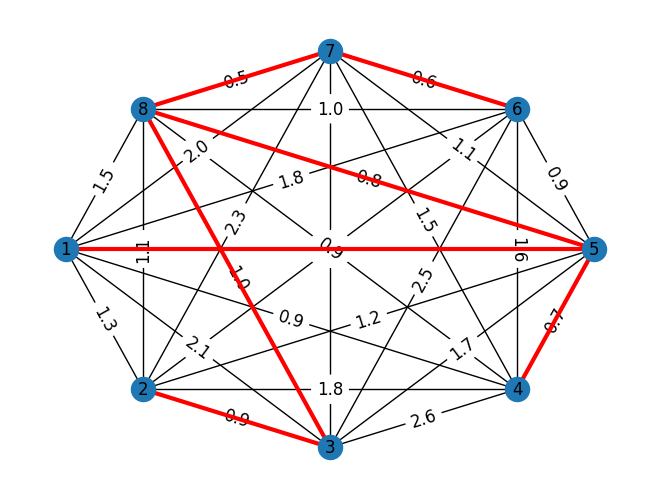

In [21]:
# 最小生成树（默认Kruskal算法）
# 返回可迭代对象
T = nx.minimum_spanning_tree(G)  
# 返回最小生成树的邻接矩阵
# d = nx.to_numpy(T)  
d = nx.to_scipy_sparse_array(T)
print("邻接矩阵c=\n",d)
# 求油管长度（对称矩阵和的一半加5英里）
W = d.sum()/2+5  
print("油管长度W=",W)
w1=nx.get_edge_attributes(T,'weight')
# 绘图 
# 绘制连接图G和G的最小生成树图像
nx.draw(G,pos,with_labels=True,labels = s)
nx.draw_networkx_edge_labels(G,pos,font_size=12,edge_labels=w)
nx.draw_networkx_edges(T,pos,edgelist=w1.keys(),
             edge_color='r',width=3)
plt.show()

## 5. 小结

本次实验介绍了最小生成树中的Kruskal算法和Prim算法的基本思路和一般步骤，并且通过一个实例使用networkx库计算最小生成树。

通过本次实验需要掌握以下内容：
- 掌握Kruskal算法的思路
- 掌握Prim算法的思路
- 掌握使用networkx计算最小生成树